In [ ]:
import os

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import numpy as np
from datasets import load_dataset
from transformers import AutoTokenizer, AutoConfig
import matplotlib.pyplot as plt
import os

from models.bert_model import BertModel, load_weights_from_checkpoint
from models.kan_bert import KanBertModel
from models.utils import *

print("TensorFlow Version:", tf.__version__)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

TensorFlow Version: 2.19.0


In [ ]:
class ExperimentConfig:
    MODEL_NAME = 'prajjwal1/bert-tiny'
    CHECKPOINT_PATH = 'BERT_tiny/bert_model.ckpt'
    MAX_LENGTH = 128
    KAN_INTERMEDIATE_SIZE = 16
    KAN_GRID_SIZE = 8
    EPOCHS = 7
    BATCH_SIZE = 128
    LEARNING_RATE = 4e-5

def get_glue_dataset(tokenizer, dataset_name, max_length, batch_size):
    """
    Carga, tokeniza y prepara un dataset de GLUE usando una lógica robusta
    para manejar los diferentes nombres de columna.
    """
    print(f"\nCargando y procesando el dataset '{dataset_name}'...")
    validation_split = 'validation_matched' if dataset_name == 'mnli' else 'validation'
    raw_datasets = load_dataset("glue", dataset_name)
    num_labels = raw_datasets["train"].features["label"].num_classes
    print(f"El dataset tiene {num_labels} clases.")

    def preprocess_function(examples):

        text_cols = [col for col in examples.keys() if col not in ['label', 'idx']]

        text_cols.sort()

        args = (examples[text_cols[0]],) if len(text_cols) == 1 else (examples[text_cols[0]], examples[text_cols[1]])

        return tokenizer(*args, truncation=True, padding='max_length', max_length=max_length)

    tokenized_datasets = raw_datasets.map(preprocess_function, batched=True)

    tf_columns = ['input_ids', 'token_type_ids', 'attention_mask']

    tf_train_dataset = tokenized_datasets["train"].to_tf_dataset(
        columns=tf_columns,
        label_cols=["label"],
        shuffle=True,
        batch_size=batch_size
    ).prefetch(tf.data.AUTOTUNE)

    tf_validation_dataset = tokenized_datasets[validation_split].to_tf_dataset(
        columns=tf_columns,
        label_cols=["label"],
        shuffle=False,
        batch_size=batch_size
    ).prefetch(tf.data.AUTOTUNE)

    print("Dataset convertido a formato tf.data.Dataset exitosamente.")
    return tf_train_dataset, tf_validation_dataset, num_labels


def run_experiment(model_type, train_dataset, validation_dataset, num_labels, config):
    print("\n" + "="*60)
    print(f"--- Iniciando Experimento para el Modelo: {model_type.upper()} ---")
    print("="*60)

    hf_config = AutoConfig.from_pretrained(config.MODEL_NAME)
    model_config = {
        'vocab_size': hf_config.vocab_size, 'max_position_embeddings': hf_config.max_position_embeddings,
        'type_vocab_size': hf_config.type_vocab_size, 'hidden_size': hf_config.hidden_size,
        'num_heads': hf_config.num_attention_heads, 'num_layers': hf_config.num_hidden_layers,
        'intermediate_size': hf_config.intermediate_size, 'dropout_rate': 0.1,
        'kan_intermediate_size': config.KAN_INTERMEDIATE_SIZE, 'kan_grid_size': config.KAN_GRID_SIZE
    }

    if model_type == 'bert': base_model = BertModel(model_config, name=f'bert_{config.DATASET_NAME}') # Nombre único
    else: base_model = KanBertModel(model_config, name=f'kan_bert_{config.DATASET_NAME}') # Nombre único

    dummy_input_ids = tf.zeros((1, config.MAX_LENGTH), dtype=tf.int32)
    dummy_segment_ids = tf.zeros((1, config.MAX_LENGTH), dtype=tf.int32)
    _ = base_model([dummy_input_ids, dummy_segment_ids])

    print("\nCargando pesos pre-entrenados...")
    if model_type == 'bert':
        exclude_list = ["encoder/layer_0/intermediate", "encoder/layer_0/output/dense",
                        "encoder/layer_1/intermediate", "encoder/layer_1/output/dense"]
        load_weights_from_checkpoint(base_model, config.CHECKPOINT_PATH, exclude_strings=exclude_list)
    else:
        load_weights_from_checkpoint(base_model, config.CHECKPOINT_PATH)

    input_ids = tf.keras.Input(shape=(config.MAX_LENGTH,), dtype=tf.int32, name="input_ids")
    token_type_ids = tf.keras.Input(shape=(config.MAX_LENGTH,), dtype=tf.int32, name="token_type_ids")

    pooled_output, _ = base_model([input_ids, token_type_ids], return_sequence=True)
    dropout = tf.keras.layers.Dropout(0.1)(pooled_output)

    classifier = tf.keras.layers.Dense(num_labels, activation='softmax', name="classifier")(dropout)
    loss_function = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)

    model = tf.keras.Model(inputs=[input_ids, token_type_ids], outputs=classifier)
    optimizer = tf.keras.optimizers.Adam(learning_rate=config.LEARNING_RATE)
    model.compile(optimizer=optimizer, loss=loss_function, metrics=['accuracy'])

    print(f"\nResumen del modelo {model_type.upper()} para entrenamiento:")
    model.summary(line_length=100)
    print(f"\nIniciando entrenamiento para {model_type.upper()}...")
    history = model.fit(train_dataset, validation_data=validation_dataset, epochs=config.EPOCHS)

    print(f"\nEntrenamiento para {model_type.upper()} completado.")
    return history

In [ ]:
# CELDA 3: EXPERIMENTO 1: CLASIFICACIÓN BINARIA (Dataset: SST-2)
# ===============================================================

print("INICIANDO EXPERIMENTO 1: CLASIFICACIÓN BINARIA")
exp1_config = ExperimentConfig()
exp1_config.DATASET_NAME = 'sst2'

tokenizer = AutoTokenizer.from_pretrained(exp1_config.MODEL_NAME)
train_ds_sst2, val_ds_sst2, n_labels_sst2 = get_glue_dataset(tokenizer, exp1_config.DATASET_NAME, exp1_config.MAX_LENGTH, exp1_config.BATCH_SIZE)

INICIANDO EXPERIMENTO 1: CLASIFICACIÓN BINARIA


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]


Cargando y procesando el dataset 'sst2'...


...

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

/usr/local/lib/python3.11/dist-packages/datasets/arrow_dataset.py:403: FutureWarning: The output of `to_tf_dataset` will change when a passing single element list for `labels` or `columns` in the next datasets version. To return a tuple structure rather than dict, pass a single string.
Old behaviour: columns=['a'], labels=['labels'] -> (tf.Tensor, tf.Tensor)  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor)  
New behaviour: columns=['a'],labels=['labels'] -> ({'a': tf.Tensor}, {'labels': tf.Tensor})  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor) 
  warnings.warn(


Dataset convertido a formato tf.data.Dataset exitosamente.


In [ ]:
history_bert_sst2 = run_experiment('bert', train_ds_sst2, val_ds_sst2, n_labels_sst2, exp1_config)
history_kanbert_sst2 = run_experiment('kanbert', train_ds_sst2, val_ds_sst2, n_labels_sst2, exp1_config)


--- Iniciando Experimento para el Modelo: BERT ---

Cargando pesos pre-entrenados (MODO DE COMPARACIÓN JUSTA)...

Cargados 31 de 39 pesos del modelo.
Pesos excluidos por el usuario (para entrenamiento de FFN):
 - bert_sst2/encoder/layer_0/intermediate/dense/kernel
 - bert_sst2/encoder/layer_0/intermediate/dense/bias
 - bert_sst2/encoder/layer_0/output/dense/kernel
 - bert_sst2/encoder/layer_0/output/dense/bias
 - bert_sst2/encoder/layer_1/intermediate/dense/kernel
 - bert_sst2/encoder/layer_1/intermediate/dense/bias
 - bert_sst2/encoder/layer_1/output/dense/kernel
 - bert_sst2/encoder/layer_1/output/dense/bias

Resumen del modelo BERT para entrenamiento:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)      │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ token_type_ids (InputLayer) │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ bert_sst2 (BertModel)       │ [(None, 128), (None,    │      4,385,920 │ input_ids[0][0],        │
│                             │ 128, 128)]              │                │ token_type_ids[0][0]    │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_5 (Dropout)         │ (None, 128)             │              0 │ bert_sst2[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ classifier (Dense)          │ (None, 2)               │            258 │ dropout_5[0][0]         │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 4,386,178 (16.73 MB)

 Trainable params: 4,386,178 (16.73 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)      │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ token_type_ids (InputLayer) │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ kan_bert_sst2               │ [(None, 128), (None,    │      4,171,822 │ input_ids[0][0],        │
│ (KanBertModel)              │ 128, 128)]              │                │ token_type_ids[0][0]    │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_11 (Dropout)        │ (None, 128)             │              0 │ kan_bert_sst2[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ classifier (Dense)          │ (None, 2)               │            258 │ dropout_11[0][0]        │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 4,172,080 (15.92 MB)

 Trainable params: 4,172,050 (15.92 MB)

 Non-trainable params: 30 (120.00 B)


Iniciando entrenamiento para KANBERT...
Epoch 1/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 69s 79ms/step - accuracy: 0.6314 - loss: 0.6342 - val_accuracy: 0.7787 - val_loss: 0.4657
Epoch 2/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.8415 - loss: 0.3683 - val_accuracy: 0.8119 - val_loss: 0.4382
Epoch 3/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.8794 - loss: 0.2951 - val_accuracy: 0.8234 - val_loss: 0.4338
Epoch 4/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9004 - loss: 0.2496 - val_accuracy: 0.8268 - val_loss: 0.4522
Epoch 5/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9130 - loss: 0.2202 - val_accuracy: 0.8245 - val_loss: 0.4679
Epoch 6/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9217 - loss: 0.2003 - val_accuracy: 0.8245 - val_loss: 0.4862
Epoch 7/7
527/527 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9270 - loss: 0.1863 - val_accuracy: 0.8257 - val_loss: 0.4965

Entrenamiento para KANBERT completado.


In [ ]:
# ==================================================================================
# --- EXPERIMENTO 2: CLASIFICACIÓN BINARIA - PARÁFRASIS (Dataset: QQP) ---
# ==================================================================================
# Tarea: Determinar si dos preguntas de Quora son semánticamente equivalentes.

print("\n\nINICIANDO EXPERIMENTO 2: QQP (Binario - Paráfrasis)")
exp2_config = ExperimentConfig()
exp2_config.DATASET_NAME = 'qqp'

train_ds_qqp, val_ds_qqp, n_labels_qqp = get_glue_dataset(tokenizer, exp2_config.DATASET_NAME, exp2_config.MAX_LENGTH, exp2_config.BATCH_SIZE)

history_bert_qqp = run_experiment('bert', train_ds_qqp, val_ds_qqp, n_labels_qqp, exp2_config)
history_kanbert_qqp = run_experiment('kanbert', train_ds_qqp, val_ds_qqp, n_labels_qqp, exp2_config)



INICIANDO EXPERIMENTO 2: QQP (Binario - Paráfrasis)

Cargando y procesando el dataset 'qqp'...


qqp/train-00000-of-00001.parquet:   0%|          | 0.00/33.6M [00:00<?, ?B/s]

qqp/validation-00000-of-00001.parquet:   0%|          | 0.00/3.73M [00:00<?, ?B/s]

qqp/test-00000-of-00001.parquet:   0%|          | 0.00/36.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/363846 [00:00<?, ? examples/s]

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)      │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ token_type_ids (InputLayer) │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ kan_bert_qqp (KanBertModel) │ [(None, 128), (None,    │      4,171,822 │ input_ids[0][0],        │
│                             │ 128, 128)]              │                │ token_type_ids[0][0]    │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_23 (Dropout)        │ (None, 128)             │              0 │ kan_bert_qqp[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ classifier (Dense)          │ (None, 2)               │            258 │ dropout_23[0][0]        │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 4,172,080 (15.92 MB)

 Trainable params: 4,172,050 (15.92 MB)

 Non-trainable params: 30 (120.00 B)


Iniciando entrenamiento para KANBERT...
Epoch 1/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 132s 38ms/step - accuracy: 0.7223 - loss: 0.5165 - val_accuracy: 0.7771 - val_loss: 0.4374
Epoch 2/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 84s 29ms/step - accuracy: 0.8063 - loss: 0.3984 - val_accuracy: 0.8085 - val_loss: 0.3984
Epoch 3/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 84s 29ms/step - accuracy: 0.8327 - loss: 0.3577 - val_accuracy: 0.8117 - val_loss: 0.3994
Epoch 4/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 84s 29ms/step - accuracy: 0.8489 - loss: 0.3302 - val_accuracy: 0.8215 - val_loss: 0.3864
Epoch 5/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 83s 29ms/step - accuracy: 0.8600 - loss: 0.3102 - val_accuracy: 0.8245 - val_loss: 0.3836
Epoch 6/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 84s 30ms/step - accuracy: 0.8693 - loss: 0.2937 - val_accuracy: 0.8322 - val_loss: 0.3724
Epoch 7/7
2843/2843 ━━━━━━━━━━━━━━━━━━━━ 84s 29ms/step - accuracy: 0.8777 - loss: 0.2767 - val_accuracy: 0.8335 - val_loss: 0.3745

Entrenamiento para KANBERT completado.


In [ ]:
# ======================================================================================
# --- EXPERIMENTO 3: CLASIFICACIÓN BINARIA - RESPUESTA A PREGUNTAS (Dataset: QNLI) ---
# ======================================================================================
# Tarea: Determinar si un pasaje de texto contiene la respuesta a una pregunta.

print("\n\nINICIANDO EXPERIMENTO 3: QNLI (Binario - QA)")
exp3_config = ExperimentConfig()
exp3_config.DATASET_NAME = 'qnli'

train_ds_qnli, val_ds_qnli, n_labels_qnli = get_glue_dataset(tokenizer, exp3_config.DATASET_NAME, exp3_config.MAX_LENGTH, exp3_config.BATCH_SIZE)

history_bert_qnli = run_experiment('bert', train_ds_qnli, val_ds_qnli, n_labels_qnli, exp3_config)
history_kanbert_qnli = run_experiment('kanbert', train_ds_qnli, val_ds_qnli, n_labels_qnli, exp3_config)



INICIANDO EXPERIMENTO 3: QNLI (Binario - QA)

Cargando y procesando el dataset 'qnli'...


qnli/train-00000-of-00001.parquet:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

qnli/validation-00000-of-00001.parquet:   0%|          | 0.00/872k [00:00<?, ?B/s]

qnli/test-00000-of-00001.parquet:   0%|          | 0.00/877k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/104743 [00:00<?, ? examples/s]

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)      │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ token_type_ids (InputLayer) │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ kan_bert_qnli               │ [(None, 128), (None,    │      4,171,822 │ input_ids[0][0],        │
│ (KanBertModel)              │ 128, 128)]              │                │ token_type_ids[0][0]    │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_35 (Dropout)        │ (None, 128)             │              0 │ kan_bert_qnli[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ classifier (Dense)          │ (None, 2)               │            258 │ dropout_35[0][0]        │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 4,172,080 (15.92 MB)

 Trainable params: 4,172,050 (15.92 MB)

 Non-trainable params: 30 (120.00 B)


Iniciando entrenamiento para KANBERT...
Epoch 1/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 72s 58ms/step - accuracy: 0.6581 - loss: 0.6233 - val_accuracy: 0.7430 - val_loss: 0.5272
Epoch 2/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.7660 - loss: 0.5026 - val_accuracy: 0.7640 - val_loss: 0.4982
Epoch 3/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.7883 - loss: 0.4683 - val_accuracy: 0.7661 - val_loss: 0.4926
Epoch 4/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.8060 - loss: 0.4351 - val_accuracy: 0.7725 - val_loss: 0.4990
Epoch 5/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.8210 - loss: 0.4099 - val_accuracy: 0.7686 - val_loss: 0.5201
Epoch 6/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.8350 - loss: 0.3844 - val_accuracy: 0.7822 - val_loss: 0.4947
Epoch 7/7
819/819 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.8440 - loss: 0.3630 - val_accuracy: 0.7633 - val_loss: 0.5437

Entrenamiento para KANBERT completado.


In [ ]:
# ====================================================================================
# --- EXPERIMENTO 4: CLASIFICACIÓN MULTICLASE - INFERENCIA (Dataset: MNLI) ---
# ====================================================================================
# Tarea: Dadas dos frases, determinar si la relación es de 'entailment', 'neutral' o 'contradiction'.

print("\n\nINICIANDO EXPERIMENTO 4: MNLI (Multiclase - Inferencia)")
exp4_config = ExperimentConfig()
exp4_config.DATASET_NAME = 'mnli'

train_ds_mnli, val_ds_mnli, n_labels_mnli = get_glue_dataset(tokenizer, exp4_config.DATASET_NAME, exp4_config.MAX_LENGTH, exp4_config.BATCH_SIZE)

history_bert_mnli = run_experiment('bert', train_ds_mnli, val_ds_mnli, n_labels_mnli, exp4_config)
history_kanbert_mnli = run_experiment('kanbert', train_ds_mnli, val_ds_mnli, n_labels_mnli, exp4_config)



INICIANDO EXPERIMENTO 4: MNLI (Multiclase - Inferencia)

Cargando y procesando el dataset 'mnli'...


mnli/train-00000-of-00001.parquet:   0%|          | 0.00/52.2M [00:00<?, ?B/s]

mnli/validation_matched-00000-of-00001.p(…):   0%|          | 0.00/1.21M [00:00<?, ?B/s]

mnli/validation_mismatched-00000-of-0000(…):   0%|          | 0.00/1.25M [00:00<?, ?B/s]

mnli/test_matched-00000-of-00001.parquet:   0%|          | 0.00/1.22M [00:00<?, ?B/s]

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)      │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ token_type_ids (InputLayer) │ (None, 128)             │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ kan_bert_mnli               │ [(None, 128), (None,    │      4,171,822 │ input_ids[0][0],        │
│ (KanBertModel)              │ 128, 128)]              │                │ token_type_ids[0][0]    │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_47 (Dropout)        │ (None, 128)             │              0 │ kan_bert_mnli[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ classifier (Dense)          │ (None, 3)               │            387 │ dropout_47[0][0]        │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 4,172,209 (15.92 MB)

 Trainable params: 4,172,179 (15.92 MB)

 Non-trainable params: 30 (120.00 B)


Iniciando entrenamiento para KANBERT...
Epoch 1/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 137s 37ms/step - accuracy: 0.4673 - loss: 1.0282 - val_accuracy: 0.6360 - val_loss: 0.8365
Epoch 2/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 90s 29ms/step - accuracy: 0.6341 - loss: 0.8312 - val_accuracy: 0.6549 - val_loss: 0.8060
Epoch 3/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 90s 29ms/step - accuracy: 0.6606 - loss: 0.7812 - val_accuracy: 0.6693 - val_loss: 0.7777
Epoch 4/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 90s 29ms/step - accuracy: 0.6792 - loss: 0.7455 - val_accuracy: 0.6742 - val_loss: 0.7607
Epoch 5/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 89s 29ms/step - accuracy: 0.6961 - loss: 0.7154 - val_accuracy: 0.6782 - val_loss: 0.7497
Epoch 6/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 88s 29ms/step - accuracy: 0.7064 - loss: 0.6933 - val_accuracy: 0.6837 - val_loss: 0.7415
Epoch 7/7
3068/3068 ━━━━━━━━━━━━━━━━━━━━ 89s 29ms/step - accuracy: 0.7182 - loss: 0.6707 - val_accuracy: 0.6872 - val_loss: 0.7575

Entrenamiento para KANBERT completado.



---           RESUMEN DE MEJORES ACCURACIES EN VALIDACIÓN           ---
                      BERT KAN-BERT Diferencia (KAN - BERT)
SST-2 (Sentimiento) 0.8096   0.8268                 +0.0172
QQP (Paráfrasis)    0.8510   0.8335                 -0.0174
QNLI (QA)           0.7825   0.7822                 -0.0004
MNLI (Inferencia)   0.7014   0.6872                 -0.0142


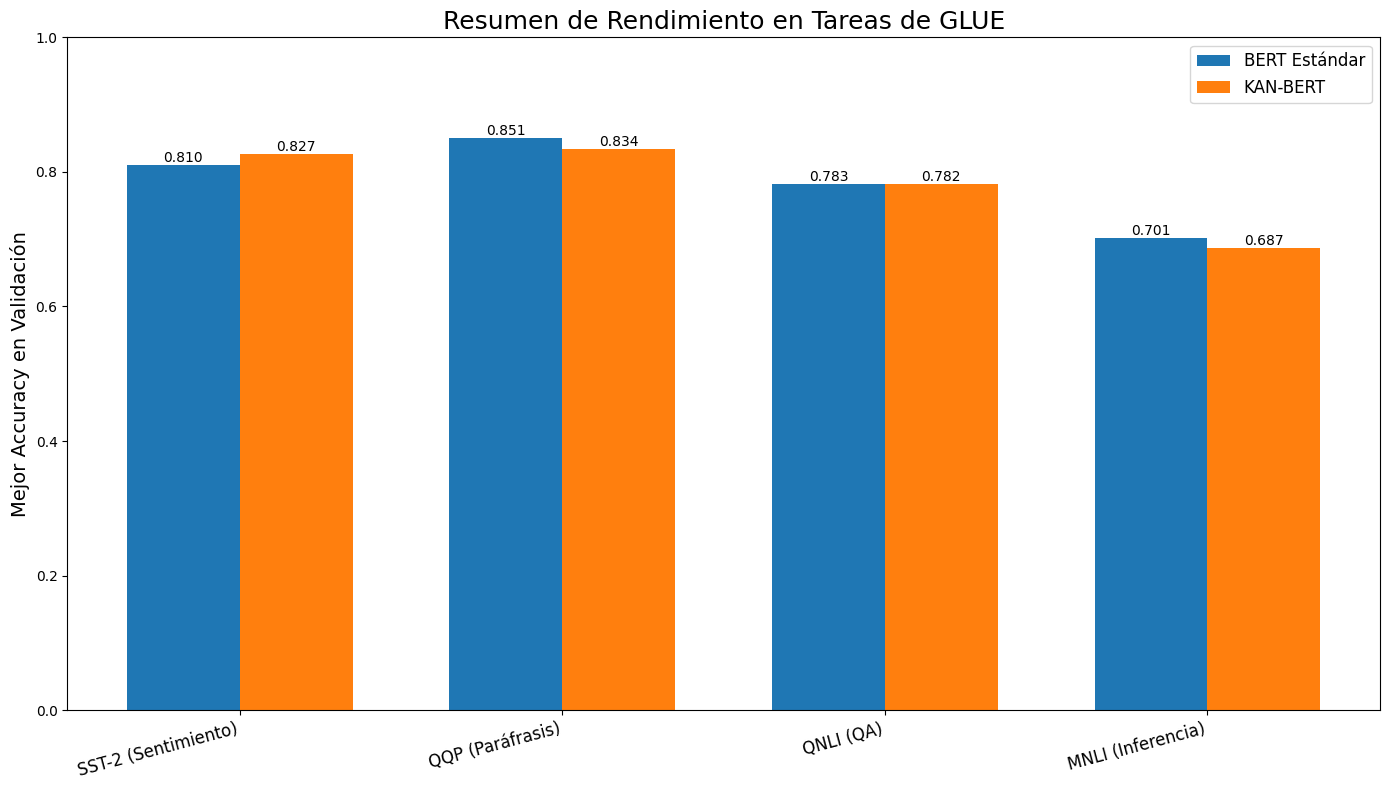

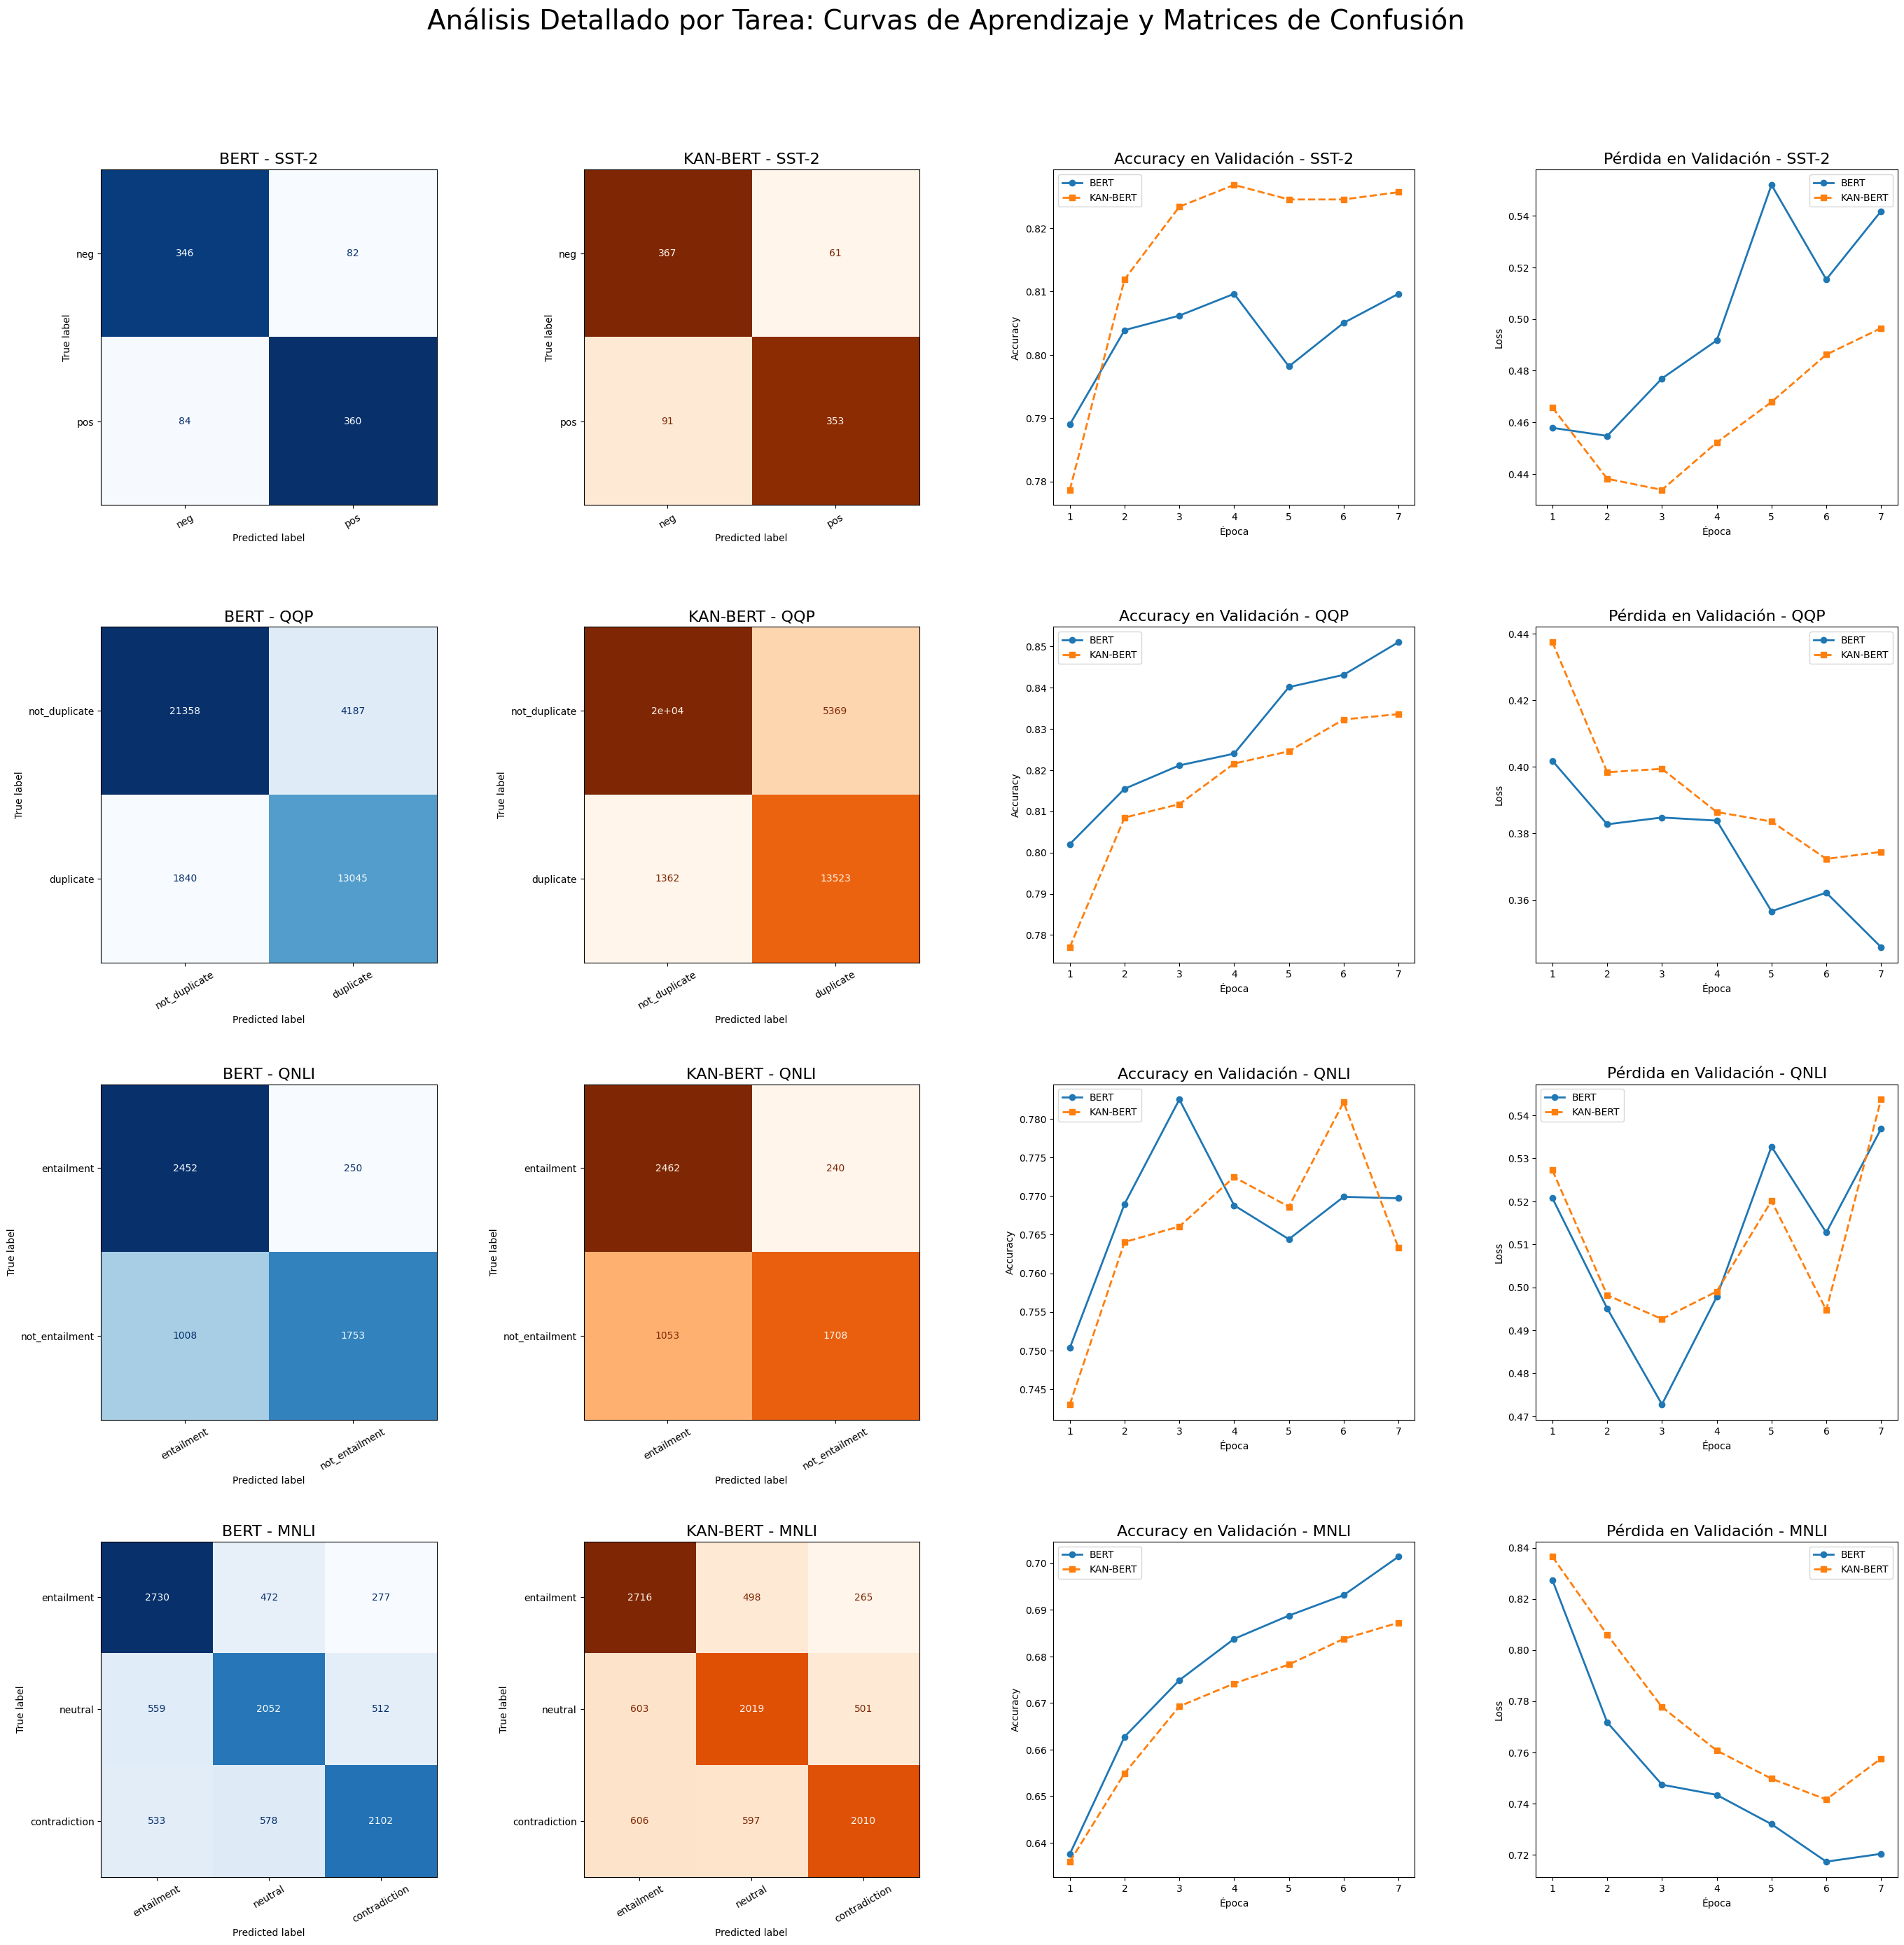

In [ ]:
# ==============================================================================
# --- ANÁLISIS FINAL Y VISUALIZACIÓN DE RESULTADOS AGREGADOS ---
# ==============================================================================
# En esta celda final, recopilamos todos los resultados, los presentamos en
# tablas y generamos un conjunto completo de visualizaciones para comparar
# el rendimiento de BERT y KAN-BERT en las cuatro tareas de GLUE.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import pandas as pd

def get_predictions_and_labels(model, validation_dataset):
    """Recorre el dataset de validación para obtener todas las predicciones y etiquetas."""
    all_predictions, all_labels = [], []
    for features, labels in validation_dataset:
        predictions = model.predict(features, verbose=0)
        predicted_class = np.argmax(predictions, axis=1)
        all_predictions.extend(predicted_class)
        all_labels.extend(labels.numpy())
    return np.array(all_predictions), np.array(all_labels)

# 1. Recopilar todos los mejores resultados de accuracy
results = {
    'SST-2 (Sentimiento)': { 'BERT': max(history_bert_sst2.history['val_accuracy']), 'KAN-BERT': max(history_kanbert_sst2.history['val_accuracy']) },
    'QQP (Paráfrasis)': { 'BERT': max(history_bert_qqp.history['val_accuracy']), 'KAN-BERT': max(history_kanbert_qqp.history['val_accuracy']) },
    'QNLI (QA)': { 'BERT': max(history_bert_qnli.history['val_accuracy']), 'KAN-BERT': max(history_kanbert_qnli.history['val_accuracy']) },
    'MNLI (Inferencia)': { 'BERT': max(history_bert_mnli.history['val_accuracy']), 'KAN-BERT': max(history_kanbert_mnli.history['val_accuracy']) }
}

# 2. Crear y mostrar un DataFrame de Pandas para un resumen tabular
df_results = pd.DataFrame(results).T
df_results['Diferencia (KAN - BERT)'] = df_results['KAN-BERT'] - df_results['BERT']

print("\n" + "="*75)
print("---           RESUMEN DE MEJORES ACCURACIES EN VALIDACIÓN           ---")
print("="*75)
print(df_results.to_string(formatters={
    'BERT': '{:,.4f}'.format,
    'KAN-BERT': '{:,.4f}'.format,
    'Diferencia (KAN - BERT)': '{:+.4f}'.format
}))
print("="*75)

# 3. Crear el gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(14, 8))
bar_width, index = 0.35, np.arange(len(df_results.index))
bar1 = ax.bar(index - bar_width/2, df_results['BERT'], bar_width, label='BERT Estándar', color='C0')
bar2 = ax.bar(index + bar_width/2, df_results['KAN-BERT'], bar_width, label='KAN-BERT', color='C1')
ax.set_ylabel('Mejor Accuracy en Validación', fontsize=14)
ax.set_title('Resumen de Rendimiento en Tareas de GLUE', fontsize=18)
ax.set_xticks(index)
ax.set_xticklabels(df_results.index, rotation=15, ha="right", fontsize=12)
ax.legend(fontsize=12)
ax.bar_label(bar1, fmt='%.3f')
ax.bar_label(bar2, fmt='%.3f')
ax.set_ylim(0, 1.0)
plt.tight_layout()
plt.show()

# 4. Generar el panel detallado con curvas de aprendizaje y matrices de confusión

# Primero, obtener todas las predicciones
# (Recreamos los modelos finales para asegurarnos de que estamos usando la versión entrenada)
all_histories = {
    'SST-2': (history_bert_sst2, history_kanbert_sst2, val_ds_sst2, ['neg', 'pos']),
    'QQP': (history_bert_qqp, history_kanbert_qqp, val_ds_qqp, ['not_duplicate', 'duplicate']),
    'QNLI': (history_bert_qnli, history_kanbert_qnli, val_ds_qnli, ['entailment', 'not_entailment']),
    'MNLI': (history_bert_mnli, history_kanbert_mnli, val_ds_mnli, ['entailment', 'neutral', 'contradiction'])
}

# Crear una figura grande para alojar todos los gráficos
fig, axes = plt.subplots(len(all_histories), 4, figsize=(28, 7 * len(all_histories)))
fig.suptitle('Análisis Detallado por Tarea: Curvas de Aprendizaje y Matrices de Confusión', fontsize=28, y=1.0)

for i, (task_name, (h_bert, h_kanbert, val_ds, labels)) in enumerate(all_histories.items()):

    # Obtener predicciones
    bert_model = tf.keras.models.Model(h_bert.model.inputs, h_bert.model.outputs)
    kanbert_model = tf.keras.models.Model(h_kanbert.model.inputs, h_kanbert.model.outputs)
    y_pred_bert, y_true = get_predictions_and_labels(bert_model, val_ds)
    y_pred_kanbert, _ = get_predictions_and_labels(kanbert_model, val_ds)

    # --- Columna 1: Matriz de Confusión BERT ---
    cm_bert = confusion_matrix(y_true, y_pred_bert)
    disp_bert = ConfusionMatrixDisplay(confusion_matrix=cm_bert, display_labels=labels)
    disp_bert.plot(ax=axes[i, 0], cmap='Blues', colorbar=False)
    axes[i, 0].set_title(f'BERT - {task_name}', fontsize=16)
    axes[i, 0].tick_params(axis='x', labelrotation=30)

    # --- Columna 2: Matriz de Confusión KAN-BERT ---
    cm_kanbert = confusion_matrix(y_true, y_pred_kanbert)
    disp_kanbert = ConfusionMatrixDisplay(confusion_matrix=cm_kanbert, display_labels=labels)
    disp_kanbert.plot(ax=axes[i, 1], cmap='Oranges', colorbar=False)
    axes[i, 1].set_title(f'KAN-BERT - {task_name}', fontsize=16)
    axes[i, 1].tick_params(axis='x', labelrotation=30)

    # --- Columna 3: Curvas de Accuracy ---
    ax_acc = axes[i, 2]
    ax_acc.plot(h_bert.history['val_accuracy'], 'o-', label='BERT', color='C0', linewidth=2)
    ax_acc.plot(h_kanbert.history['val_accuracy'], 's--', label='KAN-BERT', color='C1', linewidth=2)
    ax_acc.set_title(f'Accuracy en Validación - {task_name}', fontsize=16)
    ax_acc.set_xlabel('Época'); ax_acc.set_ylabel('Accuracy'); ax_acc.legend()
    ax_acc.set_xticks(range(exp1_config.EPOCHS)); ax_acc.set_xticklabels([i+1 for i in range(exp1_config.EPOCHS)])

    # --- Columna 4: Curvas de Loss ---
    ax_loss = axes[i, 3]
    ax_loss.plot(h_bert.history['val_loss'], 'o-', label='BERT', color='C0', linewidth=2)
    ax_loss.plot(h_kanbert.history['val_loss'], 's--', label='KAN-BERT', color='C1', linewidth=2)
    ax_loss.set_title(f'Pérdida en Validación - {task_name}', fontsize=16)
    ax_loss.set_xlabel('Época'); ax_loss.set_ylabel('Loss'); ax_loss.legend()
    ax_loss.set_xticks(range(exp1_config.EPOCHS)); ax_loss.set_xticklabels([i+1 for i in range(exp1_config.EPOCHS)])

plt.tight_layout(pad=3.0, h_pad=4.0, rect=[0, 0, 1, 0.97])
plt.show()